# Checking the USGS Dredge Data

Everything later in my analysis gets compared against the data release behind Alessi, Chirico and Millones (2023), which compared three dredge detectors on the Madeira River using seven Sentinel-1 scenes from June 4th to July 10th, 2019 (doi:10.5066/P9OML7YH). This notebook checks that the files match the paper, makes sure I can reproduce the paper's scores, and confirms that the hand-made labels sit on visible objects. The paths, the point loading and the scoring live in `helpers.py`, since every notebook uses them.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import requests
from sklearn.cluster import DBSCAN

from helpers import BLUE, ORANGE, OUT, RAW, TOL, chip, load_points, prf, score

OUT.mkdir(exist_ok=True)


def fetch(item_id, wanted, folder):
    """download the files of a sciencebase item whose names pass `wanted`, skipping ones already on disk."""
    item = requests.get(f"https://www.sciencebase.gov/catalog/item/{item_id}?format=json", timeout=60).json()
    folder.mkdir(parents=True, exist_ok=True)
    # files sit at the item level and inside facets
    for f in item.get("files", []) + [f for facet in item.get("facets", []) for f in facet["files"]]:
        path = folder / f["name"]
        if wanted(f["name"]) and not path.exists():
            with requests.get(f["downloadUri"], stream=True, timeout=300) as r, open(path, "wb") as fh:
                r.raise_for_status()
                for block in r.iter_content(2**20):  # 1 mb at a time, so big scenes don't sit in memory
                    fh.write(block)

The data release has four point layers, each with a scene date. *Visual* is the ground truth; analysts kept a point only when a bright object showed up in both polarizations (VV & VH) and a dredge was visible in optical imagery within one or two days. *SUMO* (an ocean ship detector), *Local* (pixels much brighter than their neighborhood) and *Global* (one threshold per scene) are the three methods the paper compares. There's no "not a dredge" class, so negatives will be automated detections that don't match a label.

In [2]:
# skip the arcgis index files (.sbn, .sbx)
fetch("654bd579d34ee4b6e05c2a74", lambda n: n.startswith("Madeira_Dredges") and not n.endswith((".sbn", ".sbx")), RAW / "labels")
data = {m: load_points(m, keep_invalid=True) for m in ["Visual", "SUMO", "Local", "Global"]}
vis = load_points("Visual")  # the labels with usable locations

print("label with no usable location:", data["Visual"].drop(vis.index)["date"].dt.date.tolist())
pd.DataFrame({"points": {m: len(g) for m, g in data.items()}, "paper (Table 4)": {"Visual": 205, "SUMO": 159, "Local": 254, "Global": 138}})

label with no usable location: [datetime.date(2019, 6, 16)]


,points,paper (Table 4)
Visual,205,205
SUMO,159,159
Local,254,254
Global,138,138


All four counts match the paper. One Visual point from June 16th has a weird coordinate and might be a placeholder for a missing location, so it counts as a missed dredge when I reproduce the paper's scores, but otherwise I drop it, leaving 204 usable labels.

In [3]:
per_date = pd.DataFrame({m: g["date"].dt.strftime("%Y-%m-%d").value_counts() for m, g in data.items()}).sort_index()
per_date.loc["Total"] = per_date.sum()  # should match table 4
per_date

,Visual,SUMO,Local,Global
date,,,,
2019-06-04,29,16,46,24
2019-06-10,32,21,42,33
2019-06-16,34,22,39,7
2019-06-22,32,24,32,13
2019-06-28,28,18,43,20
2019-07-04,25,30,21,18
2019-07-10,25,28,31,23
Total,205,159,254,138


The Visual layer holds between 25 & 34 dredges per scene. The Local method returns more points than there are dredges on five of the seven dates. Each dredge can match only one detection, so the surplus sets a floor of 53 false alarms across the seven dates, 17 of them on June 4th. Global ranges from 7 to 33 points, maybe because its threshold is set separately for each scene.

## Reproducing the paper's scores

A detection is a *true positive* (TP) if it marks a labeled dredge and a *false positive* (FP) if it doesn't. A labeled dredge that no detection marks is a *false negative* (FN). *Precision* is TP / (TP + FP), *recall* is TP / (TP + FN), and *F1* is their harmonic mean. I score every model in this project the same way.

The paper counts detections "in the same location" as a label as true positives, but it doesn't give a distance in the passages I read. So my rule pairs a detection w/ a label from the same scene if they're within some distance, and each label can be claimed only once, so a second detection on the same dredge counts as a false positive. Pairs are assigned to keep the total distance as small as possible. I try distances from 10m to 200m and compare the true positives with the paper's.

In [4]:
paper = pd.DataFrame({m: prf(*c) for m, c in {"SUMO": (95, 64, 110), "Local": (156, 98, 49), "Global": (112, 26, 93)}.items()}).T
display(paper.round(3))  # my precision, recall and f1 from the paper's table 4 counts

tolerances = [10, 20, 30, 50, 75, 100, 150, 200]
tp = pd.DataFrame({m: [score(data[m], data["Visual"], tol)["TP"] for tol in tolerances] for m in paper.index},
                  index=pd.Index(tolerances, name="matching distance (m)"))
tp.loc["paper"] = paper["TP"].astype(int)
tp

,TP,FP,FN,precision,recall,F1
SUMO,95.0,64.0,110.0,0.597,0.463,0.522
Local,156.0,98.0,49.0,0.614,0.761,0.680
Global,112.0,26.0,93.0,0.812,0.546,0.653


,SUMO,Local,Global
matching distance (m),,,
10,2,115,85
20,20,154,106
30,40,159,111
50,91,163,111
75,96,165,112
100,96,167,112
150,97,168,114
200,97,168,114
paper,95,156,112


No single distance reproduces the numbers for all three methods. Local reaches the paper's 156 between 20m (154) and 30m (159). Global gets 111 at 30m and 112 at 75m. SUMO only matches near 75m, which suggests its points might be placed differently; it'd be good to read up on how that method works exactly, but for now I'll set it aside, since Local and Global are the methods I draw candidates from and both score better anyway (F1 0.68 and 0.65 vs. 0.52). Based on this, I score all dredges at 30m; no other single distance comes as close to the paper's counts for both Local and Global. It also fits the imagery, as Sentinel-1 pixels are 10m, so 30m lets an analyst's click and a detector's center point land up to three pixels apart on the same dredge, while staying under the 32 to 40m that separates some neighboring dredges (notebook 03).

In [5]:
pd.DataFrame({"Local at 30m": score(data["Local"], data["Visual"], TOL)}).T.round(3)

,TP,FP,FN,precision,recall,F1
Local at 30m,159.0,95.0,46.0,0.626,0.776,0.693


For now the Local method is the baseline to beat. At 30m its 254 detections match 159 labels, for a precision of 0.63, a recall of 0.78 and an F1 of 0.69. Notebook 02 builds the candidate pool from these 254 points plus the Global detections.

Moored dredges show up in several scenes, so the same dredge could land in both the training and the test data and inflate a model's scores (e.g. a model could train on a moored dredge, then get tested on the same dredge on a different date). So I group labels within 100m of each other across all dates into *sites*. The 100m is my choice, and groups can chain along a line of vessels, merging neighbors into one site.

In [6]:
# any two labels within 100m, on any date, join one site; groups can chain
site = DBSCAN(eps=100, min_samples=1).fit_predict(np.c_[vis.geometry.x, vis.geometry.y])
print(len(vis), "labels in", len(set(site)), "sites")
vis.groupby(site)["date"].nunique().value_counts().sort_index().rename_axis("dates labeled").to_frame("sites")

204 labels in 97 sites


,sites
dates labeled,
1,78
2,13
3,2
4,2
7,2


The 204 labels fall into 97 sites. 78 are labeled once, and 2 are labeled on all seven dates, so later notebooks hold out whole sites when testing.

## Do labels mark visible objects?

Here I look at the first scene, June 4th, which takes about 580 MB (all seven take about 4 GB). The paper's metadata says band 1 is VH and band 2 is VV, with 10m pixels, and the scenes were calibrated and terrain-corrected in SNAP.

18944 x 12075 px, 2 bands, float32, EPSG:4326


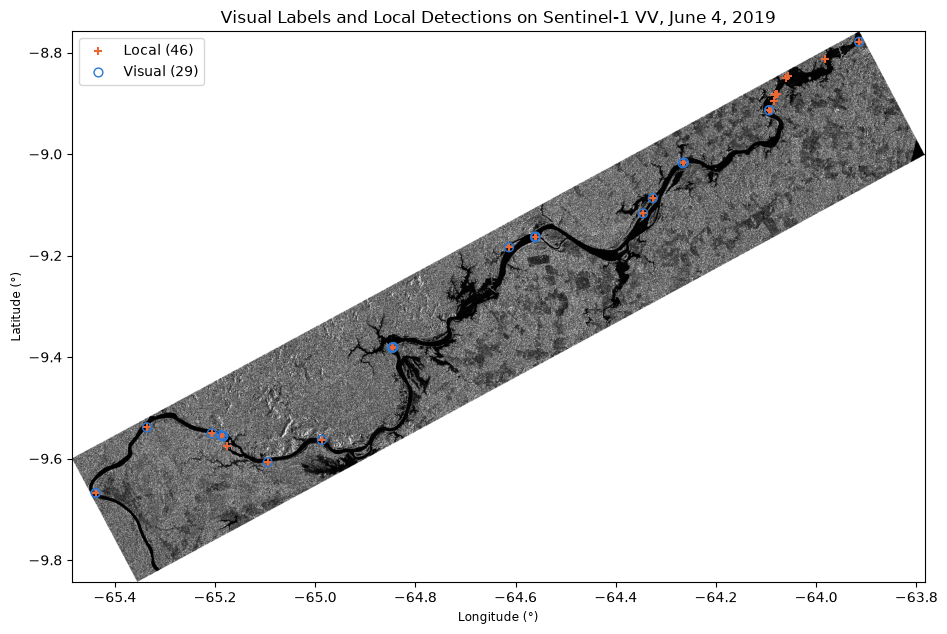

In [7]:
SCENE = RAW / "sar" / "S1A_IW_GRDH_1SDV_20190604.tif"
fetch("655388a5d34ee4b6e05c3d89", lambda n: n in (SCENE.name, "Madeira_Brazil_SAR_Metadata.xml"), SCENE.parent)

with rasterio.open(SCENE) as src:
    print(f"{src.width} x {src.height} px, {src.count} bands, {src.dtypes[0]}, {src.crs}")
    step = max(src.shape) // 2000  # every step-th pixel, just for display
    overview = src.read(2, out_shape=(src.height // step, src.width // step), masked=True)
    extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)
    june4 = {m: data[m][data[m]["date"] == "2019-06-04"].to_crs(src.crs) for m in ["Visual", "Local"]}

lo, hi = np.percentile(overview.compressed(), [2, 98])
fig, ax = plt.subplots(figsize=(11, 8))
ax.imshow(np.clip((overview - lo) / (hi - lo), 0, 1), cmap="gray", extent=extent)
june4["Local"].plot(ax=ax, color=ORANGE, marker="+", markersize=30, label=f"Local ({len(june4['Local'])})")
june4["Visual"].plot(ax=ax, facecolor="none", edgecolor=BLUE, markersize=40, label=f"Visual ({len(june4['Visual'])})")
ax.set(title="Visual Labels and Local Detections on Sentinel-1 VV, June 4, 2019", xlabel="Longitude (°)", ylabel="Latitude (°)")
ax.legend()
plt.savefig(OUT / "01_scene_overview.png", dpi=150, bbox_inches="tight")
plt.show()

The scene covers the labeled reach, and every point falls on the river, as it should. Each chip below is 64×64 pixels (about 640m wide) around one label, stretched on its own.

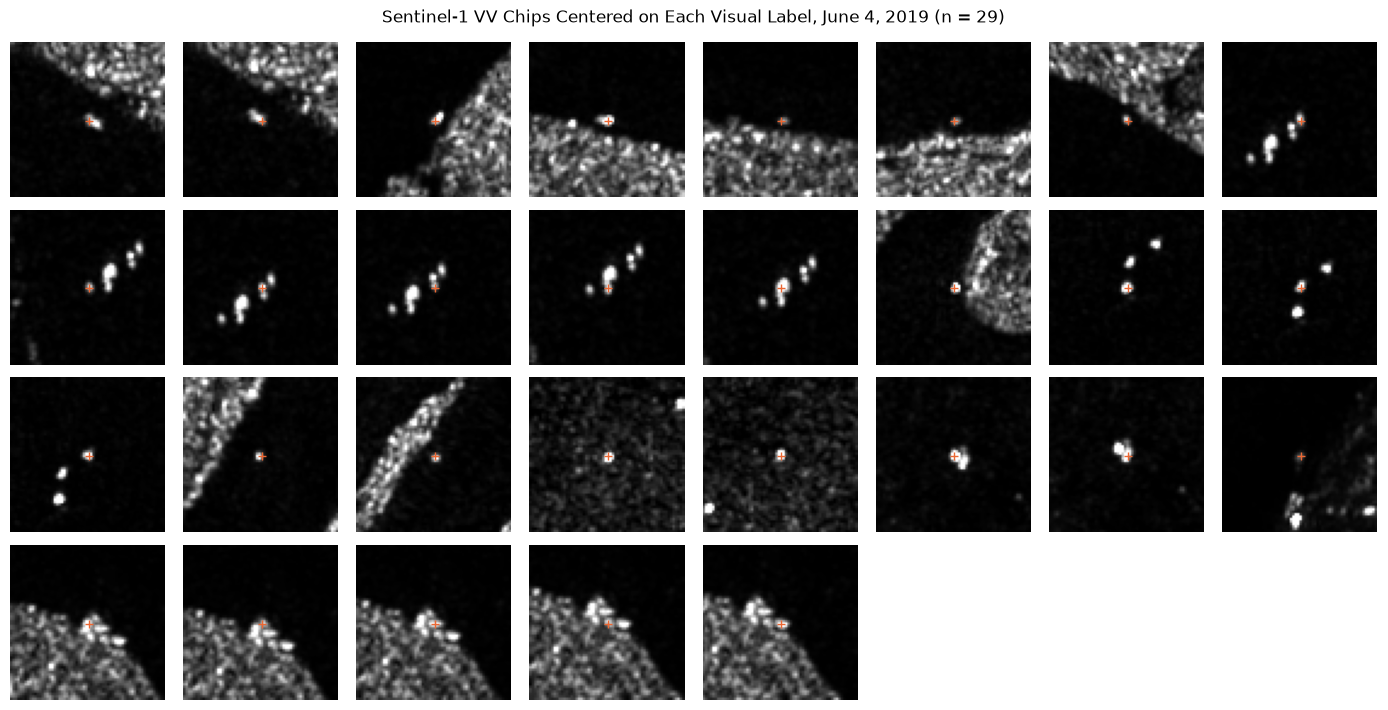

In [8]:
with rasterio.open(SCENE) as src:
    chips = [chip(src, p.x, p.y, 64, band=2) for p in june4["Visual"].geometry]

fig, axes = plt.subplots(4, 8, figsize=(14, 7.2))
for ax in axes.ravel():
    ax.axis("off")
for ax, c in zip(axes.ravel(), chips):
    # each chip gets its own stretch, so brightness only compares within a chip
    ax.imshow(c, cmap="gray", vmin=np.percentile(c, 2), vmax=np.percentile(c, 99.5))
    ax.plot(32, 32, marker="+", color=ORANGE, markersize=6)
fig.suptitle(f"Sentinel-1 VV Chips Centered on Each Visual Label, June 4, 2019 (n = {len(chips)})")
plt.tight_layout()
plt.savefig(OUT / "01_label_chips.png", dpi=150, bbox_inches="tight")
plt.show()

Almost every chip shows a compact bright object at the cross. Two patterns keep coming up -- tight groups of three to five dredges, and dredges against the bank, where land looks almost as bright as the target. To measure alignment, I find the brightest pixel within 21×21 pixels (about 210m) of each label in each band. Neighboring dredges and bright banks inside that window can get picked instead, which inflates some offsets.

In [9]:
def peak_offset(c):
    # row and column offset (px) from the window center to its brightest pixel
    return np.subtract(np.unravel_index(c.argmax(), c.shape), c.shape[0] // 2)


alignment = {}
with rasterio.open(SCENE) as src:
    for band, name in [(1, "VH (band 1)"), (2, "VV (band 2)")]:
        cs = [chip(src, p.x, p.y, 21, band) for p in june4["Visual"].geometry]
        dist = np.array([np.hypot(*peak_offset(c)) for c in cs])
        alignment[name] = {"median offset (px)": np.median(dist), "share within 2 px": np.mean(dist <= 2),
                           "median peak / chip median": np.median([c.max() / np.median(c) for c in cs])}
pd.DataFrame(alignment).T.round(2)

,median offset (px),share within 2 px,median peak / chip median
VH (band 1),5.00,0.38,38.67
VV (band 2),1.41,0.52,66.65


In VV, half the labels are within 2 pixels (20m) of the brightest pixel, and the median offset is about 1.4 pixels. VH lines up worse (5 pixels, 38%), so VV is the band to center features on, which is what the paper suggests too.

Notebook 02 reads features from each label's own scene, so here I repeat the VV check on all seven dates. I also check whether the scenes share a pixel grid & how bright the water around the labels is, since wind can raise VV and wash out a dredge's contrast.

In [10]:
# all seven scenes (~4 gb); file names end in the acquisition date
fetch("655388a5d34ee4b6e05c3d89", lambda n: n.endswith(".tif"), SCENE.parent)
with rasterio.open(SCENE) as src:
    grid0 = (src.transform, src.shape)

checks = {}
for path in sorted(SCENE.parent.glob("*.tif")):
    date = pd.Timestamp(path.stem[-8:])
    with rasterio.open(path) as src:
        cs, unreadable = [], 0
        for p in vis[vis["date"] == date].to_crs(src.crs).geometry:
            try:
                cs.append(chip(src, p.x, p.y, 21, band=2))
            except Exception:  # the june 10 file has corrupt tiles (it matches the published checksum, so the damage is in the release)
                unreadable += 1
        d = np.array([peak_offset(c) for c in cs])
        dist, water = np.hypot(d[:, 0], d[:, 1]), np.array([np.median(c) for c in cs])  # water: mostly what's around each label
        checks[f"{date:%Y-%m-%d}"] = {
            "labels": len(cs) + unreadable, "unreadable": unreadable,
            "median offset (px)": np.median(dist), "share within 2 px": np.mean(dist <= 2),
            # a shared sign across labels would mean the whole scene is shifted
            "mean row shift (px)": d[:, 0].mean(), "mean col shift (px)": d[:, 1].mean(),
            "water (VV)": np.median(water), "median peak / water": float(np.median([c.max() for c in cs] / water)),
            "same grid as June 4": (src.transform, src.shape) == grid0}
pd.DataFrame.from_dict(checks, orient="index").sort_index().round(3)

,labels,unreadable,median offset (px),share within 2 px,mean row shift (px),mean col shift (px),water (VV),median peak / water,same grid as June 4
2019-06-04,29,0,1.414,0.517,1.276,-0.414,0.013,66.652,True
2019-06-10,32,8,2.236,0.417,0.167,0.875,0.009,103.015,False
2019-06-16,33,0,1.414,0.515,1.333,-1.182,0.013,93.125,False
2019-06-22,32,0,1.000,0.719,-0.031,-0.062,0.007,99.984,False
2019-06-28,28,0,1.000,0.786,-0.036,-1.071,0.008,132.220,False
2019-07-04,25,0,1.000,0.640,-0.240,1.280,0.006,162.904,False
2019-07-10,25,0,1.000,0.720,-0.400,-0.160,0.008,110.885,False


The labels line up on every date, with median offsets of 1 to 2.2 pixels, and there's no consistent shift in any direction.

Three issues carry into the next notebook. The June 10th file is partly corrupt, so I can't read 8 of its labels; notebook 02_1 rebuilds the June 10th image from the raw Sentinel-1 data, which brings them back. The water is about twice as bright on June 4th and June 16th as on the other days (maybe from wind) and dredges stand out less on those dates, so features should measure brightness relative to the local background. And the scene grids are a bit offset (less than a pixel), which doesn't matter for reading values at coordinates, but anything that stacks dates pixel by pixel would need resampling first.

## What this all means for modeling

The data release is usable! Two things shape the problem. The candidate pool is small (254 Local detections, 295 once notebook 02 adds the Global ones) and labels repeat across dates, so testing needs to hold out whole sites. And the chips point to two features worth building next -- distance to the bank and the number of bright objects nearby. All seven scenes look fine to use, apart from the June 10th damage and the brighter water on two dates.